# β-VAE with a 2-D latent: the latent space as a map

A VAE trained on MNIST with a **2-D latent**, so the whole latent space fits on the screen. Two ideas to take away:

1. **The latent space is a map you can walk around.** Each point *z* decodes to an image; nearby points decode to similar images.
2. **β trades sharpness for coverage.** The loss is `recon + β·KL(q(z|x) ‖ N(0, I))`. Raising β blurs the reconstructions, but packs the codes into the prior, so a larger share of the prior's mass decodes to a plausible digit.

All the code lives in the `vae_demo` package; this notebook only calls it.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from vae_demo import LatentPad, get_device, train_sweep, viz

device = get_device("auto")
print(device)

cuda


## 1. Train, or load existing runs

`train_sweep` trains one model per β and saves it under `runs/beta_<β>/`. If a checkpoint is already there, it is loaded instead, so this cell takes seconds when the runs exist. Pass `skip_existing=False` to retrain (about 30 epochs, ~3 min per β on a GPU).

In [2]:
betas = [0.05, 0.1, 0.25, 1, 4, 8, 16]
runs = train_sweep(betas, out="runs", epochs=30, seed=0, device=device)
runs

loaded runs\beta_0.05
loaded runs\beta_0.1
loaded runs\beta_0.25
loaded runs\beta_1
loaded runs\beta_4
loaded runs\beta_8
loaded runs\beta_16


{0.05: Run(plain, β=0.05, evaluated at 1 β),
 0.1: Run(plain, β=0.1, evaluated at 1 β),
 0.25: Run(plain, β=0.25, evaluated at 1 β),
 1: Run(plain, β=1, evaluated at 1 β),
 4: Run(plain, β=4, evaluated at 1 β),
 8: Run(plain, β=8, evaluated at 1 β),
 16: Run(plain, β=16, evaluated at 1 β)}

## 2. The interactive pad

Drag on the plane (or focus it and use the arrow keys). Change β with the slider. Click a prior sample to jump to its *z*.

In [3]:
pad = LatentPad.from_runs(runs, beta=1)
pad

What to look for:

* **β small (0.05):** sharp digits, but the codes form separated islands with empty gaps, even inside the 86% circle. Drag into a gap: the decoder has never seen such codes, and many prior samples come out as blurry blends.
* **β = 1:** the standard VAE. The islands touch and the digits morph smoothly into each other.
* **β large (8–16):** everything is squeezed toward the origin. The prior samples look more alike and more plausible, while reconstructions blur. At β=16 whole classes merge or disappear: KL is so expensive that the model drops information about *x*.

`pad.z` and `pad.beta` sync with the widget, so you can read where the user is, or move them from Python:

In [4]:
print(pad.z, pad.beta)
# pad.z = [0.0, 2.5]; pad.beta = 8

[0.0, 0.0] 1.0


## 3. Static views

The same comparison as figures: test-set posterior means μ(x) (top) and the decoder evaluated over the same window (bottom).

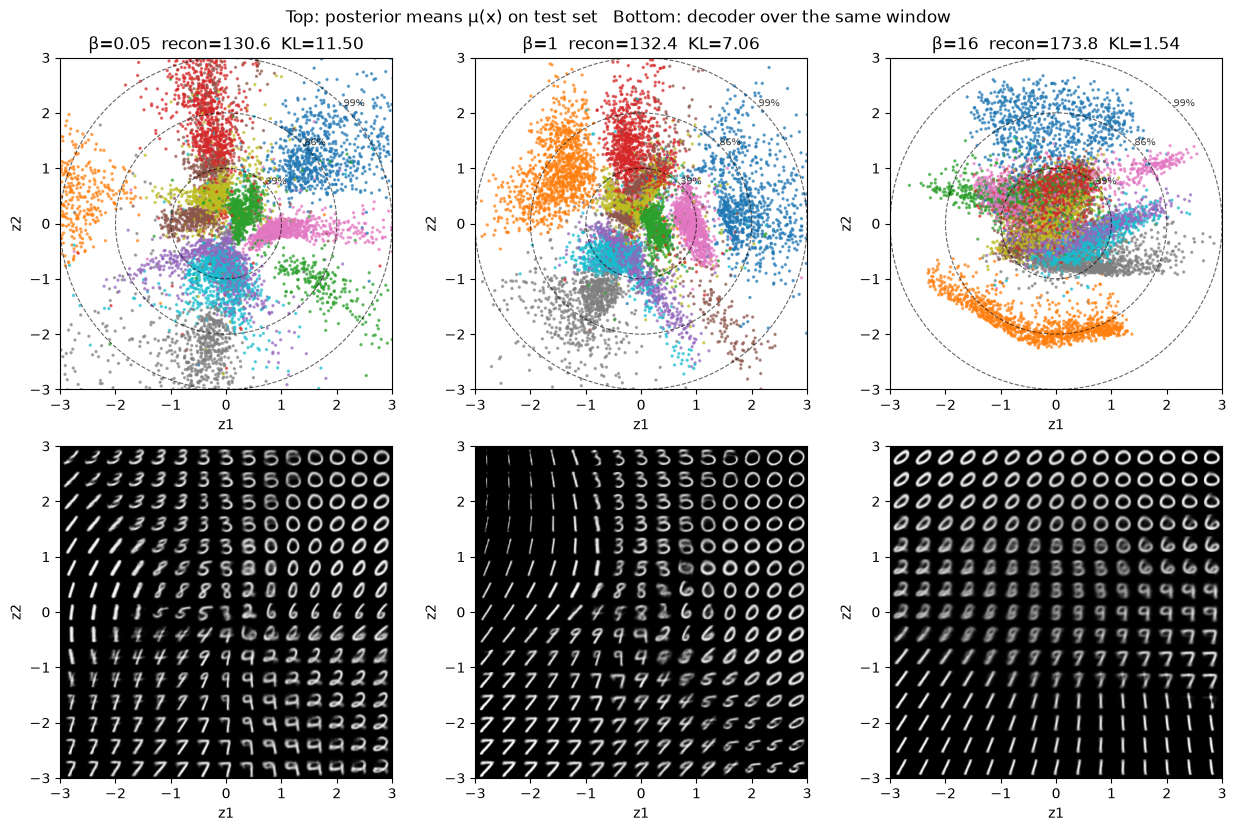

In [5]:
viz.plot_compare({b: runs[b] for b in [0.05, 1, 16]})
plt.show()

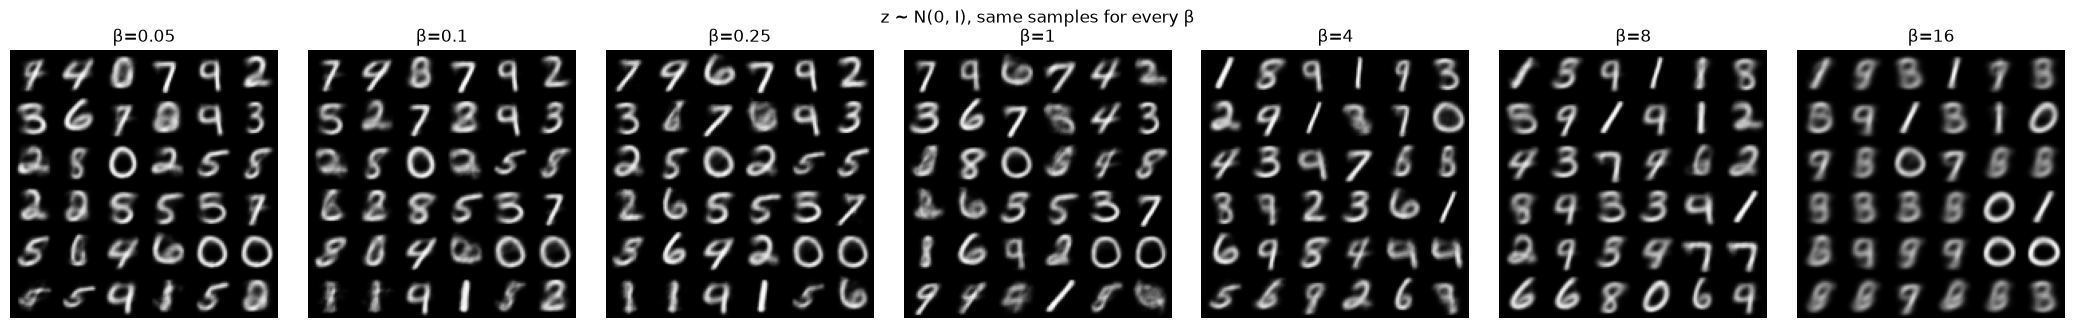

In [6]:
viz.plot_prior_samples(runs, n=6)
plt.show()

Rate–distortion: as β grows, the rate (KL) falls and the distortion (reconstruction loss) rises.

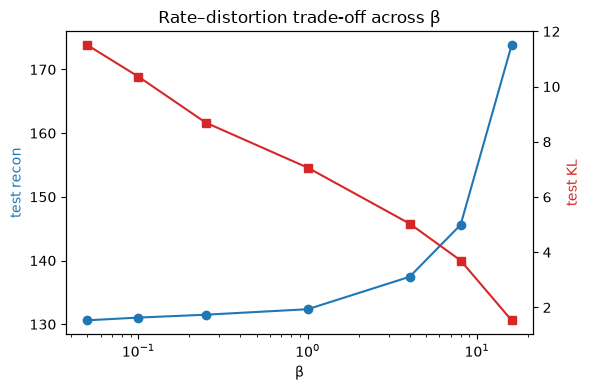

In [7]:
viz.plot_beta_summary(runs)
plt.show()

## 4. Optional: a β-conditional VAE

A single model that takes β as an input, trained with β ~ log-uniform over a range. The pad then gets a continuous β slider. This is not trained by default:

```python
from vae_demo import get_loaders, train_conditional, save_run, load_run
train_loader, test_loader = get_loaders(pin_memory=device.type == "cuda")
crun = train_conditional(train_loader, test_loader, beta_min=0.05, beta_max=16, epochs=60, device=device)
save_run(crun, "runs/cbeta")
LatentPad.from_runs(crun)
```

## 5. Publish as a static page

```bash
uv run python scripts/build_site.py          # runs/ -> docs/ (GitHub Pages: main:/docs)
```